# Лабораторная работа 1. Задача классификации

**Цель работы:** реализовать алгоритмы бинарной классификации «с нуля» на NumPy, применить их к реальному датасету и сравнить с эталонными реализациями из scikit-learn.

**Как работать с ноутбуком**

- В ячейке конфигурации (раздел 1) укажите номер задачи (зависит от группы) и номер варианта (зависит от списка).
- Ячейки с `raise NotImplementedError` или `# TODO` — ваша работа. Остальные ячейки менять не нужно.
- Алгоритмы пишутся **только на NumPy**. Pandas — для загрузки и подготовки данных, matplotlib/seaborn — для графиков. scikit-learn разрешён только в ячейках проверки и в сравнении с эталоном.
- После каждого блока стоит тест. Не переходите дальше, пока он не пройден.
- Работа принимается, если выполнены критерии из раздела 10 (качество не ниже заданного порога и не хуже эталона sklearn).
- Разрабатывайте на подвыборке (`USE_FULL_DATA = False`), финальный прогон делайте на полных данных.
- Циклов по объектам выборки в `predict` и в основных вычислениях быть не должно: используйте векторизацию.

**Задания**

1. Проанализировать датасет, привести его к числовому виду, построить корреляционную матрицу, предложить способы расширения данных.
2. Реализовать метрики качества и два классификатора: метод вашего варианта и нейронную сеть прямого распространения (MLP).
3. Подобрать гиперпараметры, обосновать выбор.
4. Оценить качество на тестовой выборке, сравнить с scikit-learn, проанализировать ошибочно классифицированные объекты.
5. Улучшить результат (обработка данных, порог, баланс классов, параметры) и сделать выводы.

**Задачи (датасеты)**

| № | Задача | Источник |
|---|--------|----------|
| 1 | Сердечно-сосудистые заболевания | [Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) |
| 2 | Качество воды | [Kaggle](https://www.kaggle.com/datasets/adityakadiwal/water-potability) |
| 3 | Стартапы | [Kaggle](https://www.kaggle.com/datasets/manishkc06/startup-success-prediction) |
| 4 | Задержка рейса | [Kaggle](https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations) |
| 5 | Вредоносные сайты | [Kaggle](https://www.kaggle.com/xwolf12/malicious-and-benign-websites) |

**Варианты**

| № варианта | Метод вашего варианта | Вторая модель |
|---|---|---|
| 1 | Наивный байесовский классификатор (гауссов) | MLP |
| 2 | Метод опорных векторов (линейный) | MLP |
| 3 | Решающее дерево | MLP |
| 4 | k ближайших соседей | MLP |
| 5 | Случайный лес (нужно реализовать и решающее дерево) — **для самостоятельного разбора** | MLP |
| 6 | Логистическая регрессия — **для самостоятельного разбора** | MLP |

Методы вариантов 5 и 6 не разбирались на занятиях: теорию изучите самостоятельно по учебным материалам.

### 1. Подготовка окружения

#### 1.1. Импорт библиотек

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", 50)

#### 1.2. Конфигурация

Укажите **свои** `TASK` и `VARIANT`. Имена файлов и целевых колонок заданы в словаре `TASKS`: сверьте их с файлами, которые вы скачали, и при необходимости поправьте.

In [2]:
TASK = 3
VARIANT = 1

SEED = 42
DATA_DIR = "."
USE_FULL_DATA = False
DEV_N = 20_000

TASKS = {
    1: dict(name="Сердечно-сосудистые заболевания", file="heart_2020_cleaned.csv", target="HeartDisease", positive="Yes"),
    2: dict(name="Качество воды", file="water_potability.csv", target="Potability", positive=1),
    3: dict(name="Стартапы", file="startup_data.csv", target="status", positive="acquired"),
    4: dict(name="Задержка рейса", file="full_data.csv", target="DEP_DEL15", positive=1),
    5: dict(name="Вредоносные сайты", file="dataset.csv", target="Type", positive=1),
}
MIN_AUC = {1: 0.8, 2: 0.65, 3: 0.70, 4: 0.60, 5: 0.85}
ACC_TOL = 0.07
METHODS = {1: "nb", 2: "svm", 3: "dt", 4: "knn", 5: "rf", 6: "logreg"}
METHOD_NAMES = {
    "rf": "Случайный лес", "svm": "SVM", "logreg": "Логистическая регрессия",
    "knn": "kNN", "nb": "Наивный Байес", "dt": "Решающее дерево",
}

cfg = TASKS[TASK]
METHOD = METHODS[VARIANT]
print(f"Задача {TASK}: {cfg['name']}")
print(f"Вариант {VARIANT}: {METHOD_NAMES[METHOD]} + MLP")


def is_mine(*keys):
    if METHOD in keys:
        return True
    print(f"Пропуск: не ваш вариант (ваш метод — {METHOD_NAMES[METHOD]})")
    return False

Задача 3: Стартапы
Вариант 1: Наивный Байес + MLP


#### 1.3. Служебные функции

Готовые функции для разбиения выборки и стандартизации. Они понадобятся дальше, менять их не нужно.

In [3]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED, stratify=True):
    r = np.random.default_rng(seed)
    n = len(y)
    if stratify:
        parts = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            r.shuffle(idx)
            parts.append(idx[: int(round(len(idx) * test_size))])
        test_idx = np.concatenate(parts)
    else:
        test_idx = r.permutation(n)[: int(round(n * test_size))]
    mask = np.zeros(n, dtype=bool)
    mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]


def subsample(X, y, n, seed=SEED):
    if len(y) <= n:
        return X, y
    idx = np.random.default_rng(seed).choice(len(y), size=n, replace=False)
    return X[idx], y[idx]


class Standardizer:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class BaseClassifier:
    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

### 2. Анализ и подготовка данных (задание 1)

#### 2.1. Загрузка

In [ ]:
df = pd.read_csv(f"{DATA_DIR}/{cfg['file']}")
print(df.shape)
df.head()

: 

#### 2.2. Описание датасета

Выведите размер датасета, список колонок и их типы, число пропусков, статистики (`describe`) и распределение целевой переменной. Ниже в markdown-ячейке опишите, что вы увидели: какие колонки что означают, есть ли пропуски, выбросы, дисбаланс классов.

In [22]:
print("Размер датасета:", df.shape)
print("\nКолонки и типы:")
print(df.dtypes.to_string())

na = df.isna().sum()
print("\nПропуски (только колонки с пропусками):")
print(na[na > 0].to_string())

print("\nЦелевая переменная status:")
print(df[cfg["target"]].value_counts())
print(df[cfg["target"]].value_counts(normalize=True).round(3).to_string())

print("\nПроверка подозрительных колонок:")
print(pd.crosstab(df["labels"], df[cfg["target"]]))
print(pd.crosstab(df["closed_at"].isna().rename("closed_at пропущен"), df[cfg["target"]]))

df.describe().T.round(2)

Размер датасета: (923, 49)

Колонки и типы:
Unnamed: 0                    int64
state_code                      str
latitude                    float64
longitude                   float64
zip_code                        str
id                              str
city                            str
Unnamed: 6                      str
name                            str
labels                        int64
founded_at                      str
closed_at                       str
first_funding_at                str
last_funding_at                 str
age_first_funding_year      float64
age_last_funding_year       float64
age_first_milestone_year    float64
age_last_milestone_year     float64
relationships                 int64
funding_rounds                int64
funding_total_usd             int64
milestones                    int64
state_code.1                    str
is_CA                         int64
is_NY                         int64
is_MA                         int64
is_TX               

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,923.0,572.30,3.335900e+02,1.00,283.50,577.00,866.50,1.153000e+03
latitude,923.0,38.52,3.740000e+00,25.75,37.39,37.78,40.73,5.934000e+01
longitude,923.0,-103.54,2.239000e+01,-122.76,-122.20,-118.37,-77.21,1.806000e+01
labels,923.0,0.65,4.800000e-01,0.00,0.00,1.00,1.00,1.000000e+00
age_first_funding_year,923.0,2.24,2.510000e+00,-9.05,0.58,1.45,3.58,2.190000e+01
age_last_funding_year,923.0,3.93,2.970000e+00,-9.05,1.67,3.53,5.56,2.190000e+01
age_first_milestone_year,771.0,3.06,2.980000e+00,-14.17,1.00,2.52,4.69,2.468000e+01
age_last_milestone_year,771.0,4.75,3.210000e+00,-7.01,2.41,4.48,6.75,2.468000e+01
relationships,923.0,7.71,7.270000e+00,0.00,3.00,5.00,10.00,6.300000e+01
funding_rounds,923.0,2.31,1.390000e+00,1.00,1.00,2.00,3.00,1.000000e+01


**Описание датасета:** датасет Startup Success Prediction: 923 американских стартапа (основаны в 1984–2013 гг.), 49 колонок. Целевая переменная `status`: `acquired` (куплен, 597 компаний, 64.7%) и `closed` (закрыт, 326, 35.3%), то есть умеренный дисбаланс в пользу положительного класса.

Колонки:
- идентификаторы и адрес (`Unnamed: 0`, `id`, `object_id`, `name`, `city`, `zip_code`, `state_code`, `latitude`, `longitude`): для модели смысла не несут;
- даты `founded_at`, `first_funding_at`, `last_funding_at`, `closed_at`;
- возраст компании в годах на момент первого/последнего финансирования и первой/последней «вехи» (`age_*_year`);
- числовые показатели: `relationships` (число связей/сотрудников в базе), `funding_rounds`, `funding_total_usd`, `milestones`, `avg_participants` (среднее число инвесторов в раунде);
- бинарные флаги: штат (`is_CA`, `is_NY`, ...), отрасль (`is_software`, `is_web`, ...), типы раундов (`has_VC`, `has_angel`, `has_roundA..D`), `is_top500`.

Пропуски: `Unnamed: 6` (493) и `state_code.1` (1) - служебные; `closed_at` (588) заполнен только у закрытых компаний; `age_first/last_milestone_year` (по 152) пропущены ровно у компаний без вех (`milestones = 0`), то есть это не случайные пропуски, а информативные.

Важные наблюдения:
- **утечка целевой переменной:** `labels` в точности повторяет `status` (кросс-таблица диагональная), а `closed_at` заполнен у всех 326 закрытых компаний (и ещё у 9 купленных) и известен только после закрытия. Обе колонки обязательно удаляются, иначе модель получит «ответ» (AUC было бы близко к 1 без всякого смысла);
- **выбросы:** `funding_total_usd` с тяжёлым правым хвостом (медиана 10 млн, 99-й перцентиль около 134 млн, максимум 5.7 млрд); у 46 компаний `age_first_funding_year < 0` (финансирование раньше официальной даты основания); координаты не согласуются с городом;
- датасет **маленький**: тестовая выборка около 184 объектов, один объект - это около 0.5 п. п. accuracy, поэтому различия в 1-2 п. п. статистически не значимы.


#### 2.3. Преобразование к числовому виду

**Приведите все признаки к числовому виду: даты и время, строковые категориальные признаки, пропуски, бинарные Yes/No и т. д.** Нечисловые колонки без смысла для модели (идентификаторы, свободный текст) можно удалить с пояснением.

**На выходе** должны быть три переменные:

- `X` — `np.ndarray` типа `float`, размер `(n_samples, n_features)`;
- `y` — `np.ndarray` из нулей и единиц (1 — положительный класс из `cfg["positive"]`);
- `feature_names` — список имён признаков.

In [ ]:

DROP_COLS = ["Unnamed: 0", "Unnamed: 6", "id", "object_id", "name", "city", "zip_code",
             "state_code", "state_code.1", "category_code", "latitude", "longitude",
             "labels", "closed_at", cfg["target"]]
DATE_COLS = ["founded_at", "first_funding_at", "last_funding_at"]
MILESTONE_COLS = ["age_first_milestone_year", "age_last_milestone_year"]
SKEWED_COLS = ["funding_total_usd", "relationships", "funding_rounds", "milestones", "avg_participants"]


def prepare(df, log_features=False):
    d = df.copy()
    y = (d[cfg["target"]] == cfg["positive"]).astype(int).to_numpy()

    # даты -> число, длительность между first and last раундом
    for c in DATE_COLS:
        d[c] = pd.to_datetime(d[c], format="%m/%d/%Y")
    d["founded_year"] = d["founded_at"].dt.year + (d["founded_at"].dt.dayofyear - 1) / 365.25
    d["last_funding_year"] = d["last_funding_at"].dt.year + (d["last_funding_at"].dt.dayofyear - 1) / 365.25
    d["funding_span_years"] = (d["last_funding_at"] - d["first_funding_at"]).dt.days / 365.25

    # пропуски: 152, заполнил 0 и добавил флаг
    d["has_milestone"] = d[MILESTONE_COLS[0]].notna().astype(int)
    d[MILESTONE_COLS] = d[MILESTONE_COLS].fillna(0.0)

    d = d.drop(columns=DROP_COLS + DATE_COLS)

    if log_features:
        for c in SKEWED_COLS:
            d[c] = np.log1p(d[c])

    return d.astype(float).to_numpy(), y, list(d.columns)


X, y, feature_names = prepare(df)
print(X.shape, feature_names)

In [24]:
assert isinstance(X, np.ndarray) and X.dtype.kind == "f" and X.ndim == 2, "X должен быть float-массивом (n, k)"
assert not np.isnan(X).any() and not np.isinf(X).any(), "в X остались NaN/inf"
assert isinstance(y, np.ndarray) and set(np.unique(y)) <= {0, 1}, "y должен состоять из 0 и 1"
assert len(X) == len(y), "X и y разной длины"
assert len(feature_names) == X.shape[1], "feature_names не соответствует числу колонок X"
print(f"OK: {X.shape[0]} объектов, {X.shape[1]} признаков, доля положительного класса {y.mean():.3f}")

OK: 923 объектов, 35 признаков, доля положительного класса 0.647


#### 2.4. Корреляционная матрица

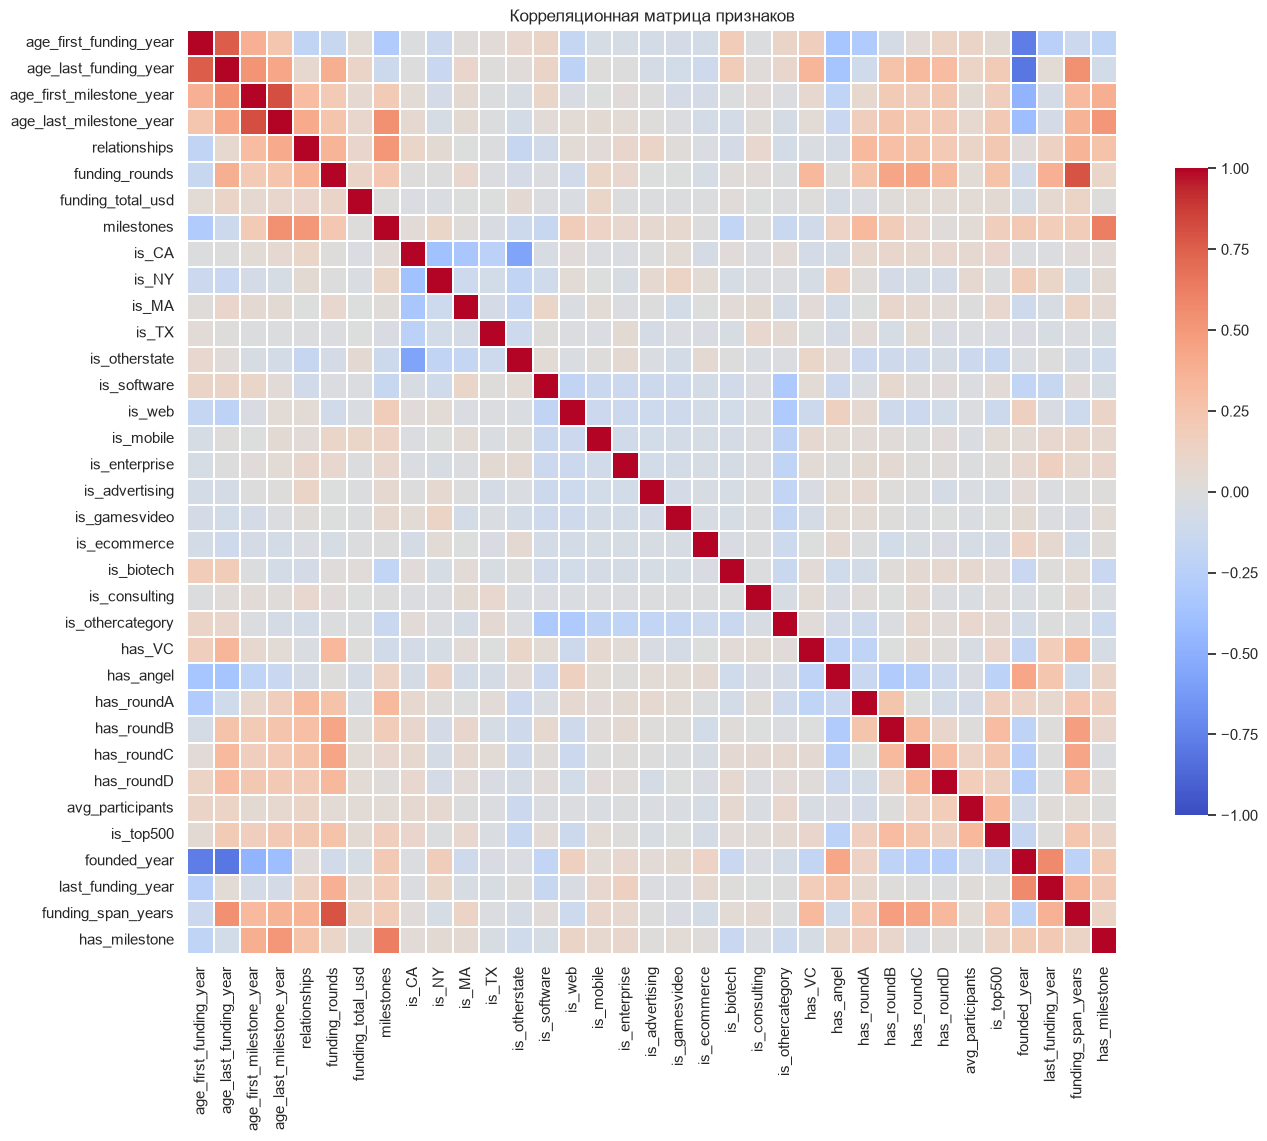

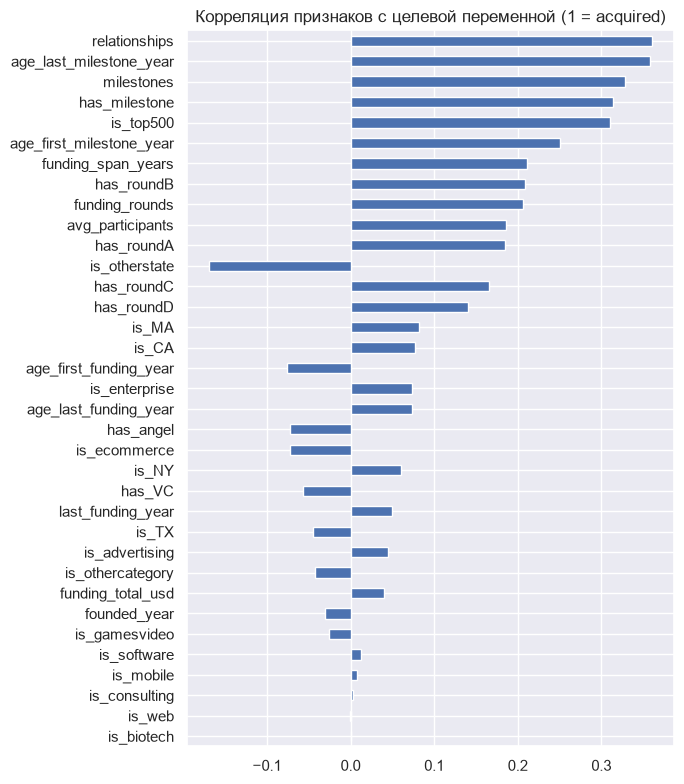

Топ-10 по |корреляции| с целевой переменной:
relationships               0.360
age_last_milestone_year     0.359
milestones                  0.328
has_milestone               0.314
is_top500                   0.311
age_first_milestone_year    0.250
funding_span_years          0.211
has_roundB                  0.208
funding_rounds              0.206
avg_participants            0.186

Пары признаков с |r| > 0.7:
  age_first_milestone_year     age_last_milestone_year      +0.813
  age_last_funding_year        founded_year                 -0.797
  funding_rounds               funding_span_years           +0.793
  age_first_funding_year       founded_year                 -0.769
  age_first_funding_year       age_last_funding_year        +0.762


In [25]:
feat_df = pd.DataFrame(X, columns=feature_names)
corr = feat_df.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2, cbar_kws={"shrink": 0.7})
plt.title("Корреляционная матрица признаков")
plt.show()

target_corr = feat_df.assign(target=y).corr()["target"].drop("target")
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
plt.figure(figsize=(7, 8))
target_corr[::-1].plot.barh()
plt.title("Корреляция признаков с целевой переменной (1 = acquired)")
plt.tight_layout()
plt.show()
print("Топ-10 по |корреляции| с целевой переменной:")
print(target_corr.head(10).round(3).to_string())

iu = np.triu_indices(len(feature_names), k=1)
pairs = [(feature_names[i], feature_names[j], corr.values[i, j]) for i, j in zip(*iu) if abs(corr.values[i, j]) > 0.7]
print("\nПары признаков с |r| > 0.7:")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:28s} {b:28s} {r:+.3f}")

**Анализ корреляций:** с целевой переменной связаны слабо: максимум около 0.36 (`relationships` 0.36, `age_last_milestone_year` 0.36, `milestones` 0.33, `has_milestone` 0.31, `is_top500` 0.31). Это ожидаемо: чем больше у компании связей, вех и чем она «заметнее», тем чаще её покупают. Слабые линейные связи означают, что задача нетривиальная и хорошего AUC (порядка 0.8) стоит ждать только от комбинации многих признаков.

Сильно коррелированные между собой признаки (|r| > 0.7): `age_first_milestone_year` и `age_last_milestone_year` (0.81), `age_last_funding_year` и `founded_year` (-0.80), `funding_rounds` и `funding_span_years` (0.79), `age_first_funding_year` и `founded_year` (-0.77), `age_first_funding_year` и `age_last_funding_year` (0.76). Это логично: возраст на момент события связан с годом основания, а число раундов - с длительностью финансирования. Что с ними можно сделать: оставить один признак из пары (с большей связью с целью), заменить их разностями/долями, применить PCA или регуляризацию. Для наивного Байеса это особенно важно, так как он предполагает условную независимость признаков, и коррелированные признаки «считаются дважды».

**Ковариация и корреляция:** ковариация $\mathrm{cov}(X,Y)=E[(X-EX)(Y-EY)]$ показывает направление совместного изменения, но зависит от масштаба и единиц измерения (её величину нельзя сравнивать между парами признаков). Корреляция Пирсона $r=\mathrm{cov}(X,Y)/(\sigma_X\sigma_Y)$ - это нормированная ковариация: безразмерная, лежит в [-1, 1] и сравнима между парами. Она измеряет только **линейную** связь (нелинейную зависимость может не заметить) и чувствительна к выбросам, а также не означает причинности.

**Как расширить датасет:** добавить данные об основателях (опыт, образование, предыдущие успешные/неуспешные компании), размере команды и её динамике; суммы и инвесторов по каждому раунду (репутация фондов); финансовые и продуктовые метрики (выручка, число пользователей, рост, отток); внешние сигналы (трафик сайта, скачивания приложений, упоминания в СМИ, патенты); макро- и рыночные показатели (размер рынка, конкуренты, ставки, состояние рынка в год основания); текстовое описание бизнеса; точную дату закрытия/сделки и больше компаний за разные годы, чтобы выборка не была такой маленькой.


#### 2.5. Разбиение выборки и стандартизация

Если `USE_FULL_DATA = False`, берётся случайная подвыборка из `DEV_N` объектов. Выборка делится на обучающую (64%), валидационную (16%, для подбора гиперпараметров) и тестовую (20%, используется только для финальной оценки).

In [26]:
if not USE_FULL_DATA:
    X, y = subsample(X, y, DEV_N)

X_tr, X_te, y_tr, y_te = train_test_split_np(X, y, test_size=0.2)
X_tr, X_val, y_tr, y_val = train_test_split_np(X_tr, y_tr, test_size=0.2)

scaler = Standardizer().fit(X_tr)
Xs_tr, Xs_val, Xs_te = (scaler.transform(a) for a in (X_tr, X_val, X_te))

print(f"train {Xs_tr.shape}, val {Xs_val.shape}, test {Xs_te.shape}")
print(f"доля положительного класса: train {y_tr.mean():.3f}, val {y_val.mean():.3f}, test {y_te.mean():.3f}")

train (591, 35), val (148, 35), test (184, 35)
доля положительного класса: train 0.646, val 0.649, test 0.647


### 3. Метрики качества (задание 2, часть 1)

Реализуйте метрики для бинарной классификации. Положительный класс — `1`. Если знаменатель равен нулю, возвращайте `0.0`.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad \text{Accuracy}=\frac{TP+TN}{n},\quad F_1=\frac{2\,P\,R}{P+R}$$

In [27]:
def confusion_matrix_np(y_true, y_pred):
    """Вернуть массив [[TN, FP], [FN, TP]]."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])


def accuracy(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    n = tn + fp + fn + tp
    return float((tn + tp) / n) if n > 0 else 0.0


def precision(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0


def recall(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0


def f1(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return float(2 * p * r / (p + r)) if (p + r) > 0 else 0.0

In [28]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

r = np.random.default_rng(0)
yt, yp = r.integers(0, 2, 500), r.integers(0, 2, 500)
assert np.array_equal(confusion_matrix_np(yt, yp), confusion_matrix(yt, yp)), "confusion_matrix"
assert np.isclose(accuracy(yt, yp), accuracy_score(yt, yp)), "accuracy"
assert np.isclose(precision(yt, yp), precision_score(yt, yp)), "precision"
assert np.isclose(recall(yt, yp), recall_score(yt, yp)), "recall"
assert np.isclose(f1(yt, yp), f1_score(yt, yp)), "f1"
assert precision(yt, np.zeros(500, dtype=int)) == 0.0, "деление на ноль в precision"
print("Метрики: OK")

Метрики: OK


In [29]:
def report(y_true, y_pred):
    return dict(accuracy=accuracy(y_true, y_pred), precision=precision(y_true, y_pred),
                recall=recall(y_true, y_pred), f1=f1(y_true, y_pred))


def plot_confusion(y_true, y_pred, title="", ax=None):
    sns.heatmap(confusion_matrix_np(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
    (ax or plt.gca()).set_title(title)

### 4. Реализация алгоритмов (задание 2, часть 2)

Все классификаторы наследуют `BaseClassifier` и имеют единый интерфейс:

- `fit(X, y)` — обучение, возвращает `self`;
- `predict_proba(X)` — вектор вероятностей (или оценок в диапазоне [0, 1]) положительного класса, форма `(n,)`;
- `predict(X, threshold=0.5)` — уже реализован в базовом классе.

Реализовывать нужно **метод своего варианта** и **MLP** (раздел 4.8). Остальные разделы пропустите: их тесты выведут «Пропуск».

#### 4.1. Вспомогательные функции и проверочные данные

In [30]:
def sigmoid(z):
    """Устойчивая сигмоида: без переполнения при больших по модулю z."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

In [31]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    z = np.array([-1000.0, -1.0, 0.0, 1.0, 1000.0])
    s = sigmoid(z)
assert np.allclose(s, [0.0, 1 / (1 + np.e), 0.5, np.e / (1 + np.e), 1.0]), "значения сигмоиды"
print("sigmoid: OK")

sigmoid: OK


Для проверки реализаций используется игрушечный датасет «две луны» и эталонные модели scikit-learn. Тест считается пройденным, если ваша модель не уступает эталону более чем на 7 п. п. accuracy.

In [32]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.svm import LinearSVC as SkSVC
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.naive_bayes import GaussianNB as SkNB
from sklearn.neural_network import MLPClassifier as SkMLP


warnings.filterwarnings("ignore", category=ConvergenceWarning)


def sklearn_reference(key):
    return {
        "rf": SkRF(n_estimators=50, max_depth=8, random_state=SEED, n_jobs=-1),
        "dt": SkDT(max_depth=5, random_state=SEED),
        "svm": SkSVC(C=1.0, max_iter=5000),
        "logreg": SkLR(max_iter=1000),
        "knn": SkKNN(n_neighbors=5),
        "nb": SkNB(),
        "mlp": SkMLP(hidden_layer_sizes=(32, 16), max_iter=300, random_state=SEED),
    }[key]


Xm, ym = make_moons(600, noise=0.25, random_state=0)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split_np(Xm, ym, test_size=0.3, seed=0)


def check_model(model, key, min_acc=0.8, tol=0.07):
    ref = sklearn_reference(key)
    model.fit(Xt_tr, yt_tr)
    ref.fit(Xt_tr, yt_tr)
    proba = model.predict_proba(Xt_te)
    assert proba.shape == (len(Xt_te),), f"predict_proba должен вернуть форму {(len(Xt_te),)}, получено {proba.shape}"
    assert np.all((proba >= 0) & (proba <= 1)), "вероятности вне [0, 1]"
    acc, acc_ref = accuracy(yt_te, model.predict(Xt_te)), ref.score(Xt_te, yt_te)
    assert acc >= min_acc and acc >= acc_ref - tol, f"accuracy {acc:.3f} (sklearn {acc_ref:.3f})"
    print(f"OK: accuracy {acc:.3f} (sklearn {acc_ref:.3f})")
    return model

#### 4.2. Решающее дерево (варианты 3 и 5)

Бинарное дерево с критерием Джини. Для двух классов с долей положительных $p$: $G = 2p(1-p)$. Прирост информации при разбиении:

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$$

Требования:

- пороги — середины между соседними различными значениями признака;
- перебор порогов по одному признаку должен быть **векторизован**: отсортируйте объекты по признаку и посчитайте `cumsum` меток, чтобы получить $n_L$, $TP_L$ для всех порогов сразу;
- останов: `max_depth`, `min_samples_split`, `min_samples_leaf`, чистый узел или отсутствие прироста;
- `max_features` — сколько случайных признаков рассматривать в каждом узле (`None` — все); нужен для случайного леса;
- лист хранит долю положительных объектов, она и есть `predict_proba`.

In [33]:
class DecisionTree(BaseClassifier):
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, max_features=None, seed=SEED):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng(seed)

    def _gini(self, y):
        raise NotImplementedError

    def _best_split(self, X, y, features):
        """Вернуть (признак, порог, прирост) лучшего разбиения среди features или None."""
        raise NotImplementedError

    def _build(self, X, y, depth):
        """Рекурсивно построить узел (например, словарь) и вернуть его."""
        raise NotImplementedError

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [34]:
if is_mine("dt", "rf"):
    check_model(DecisionTree(max_depth=5), "dt")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.3. Случайный лес (вариант 5, для самостоятельного разбора)

Ансамбль из `n_estimators` деревьев из раздела 4.2 (его тоже нужно реализовать). Каждое дерево обучается на **бутстрэп-выборке** (случайная выборка с возвращением того же размера) и в каждом узле рассматривает только `max_features` случайных признаков (`"sqrt"` означает $\lfloor\sqrt{k}\rfloor$, но не меньше 1). Итоговая вероятность — среднее вероятностей деревьев.

In [35]:
class RandomForest(BaseClassifier):
    def __init__(self, n_estimators=50, max_depth=8, max_features="sqrt", min_samples_leaf=1, seed=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [ ]:
if is_mine("rf"):
    check_model(RandomForest(n_estimators=30, max_depth=6), "rf")

#### 4.4. Метод опорных векторов (вариант 2)

Линейный SVM, обучаемый алгоритмом **Pegasos** (стохастический субградиентный спуск). Метки переводятся в $\{-1,+1\}$. Минимизируется

$$\frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{n}\sum_i \max\bigl(0,\;1 - y_i(w^\top x_i + b)\bigr)$$

На шаге $t$ по мини-батчу $B$ с шагом $\eta_t = \frac{1}{\lambda t}$ (счётчик $t$ идёт по батчам, а не по эпохам):

$$w \leftarrow (1-\eta_t\lambda)\,w + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i x_i,\qquad b \leftarrow b + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i$$

где $B_{\text{viol}}$ — объекты батча с $y_i(w^\top x_i+b)<1$. Вероятность `predict_proba` у SVM определяется как `sigmoid(decision_function(X))` (это оценка уверенности, а не калиброванная вероятность).

In [37]:
class LinearSVM(BaseClassifier):
    def __init__(self, lam=1e-2, n_epochs=20, batch_size=64, seed=SEED):
        self.lam = lam
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def decision_function(self, X):
        raise NotImplementedError

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [38]:
if is_mine("svm"):
    check_model(LinearSVM(), "svm")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.5. Логистическая регрессия (вариант 6, для самостоятельного разбора)

$p_i=\sigma(w^\top x_i + b)$. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией, обучение — градиентный спуск по всей выборке:

$$\nabla_w = \frac{1}{n}X^\top(p-y) + \lambda w,\qquad \nabla_b = \frac{1}{n}\sum_i (p_i-y_i)$$

Сохраняйте значение функции потерь на каждой эпохе в `self.loss_history`, это пригодится для графика сходимости.

In [39]:
class LogisticRegression(BaseClassifier):
    def __init__(self, lr=0.5, n_epochs=300, l2=0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.l2 = l2

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [ ]:
if is_mine("logreg"):
    m = check_model(LogisticRegression(), "logreg")
    assert m.loss_history[-1] < m.loss_history[0], "функция потерь не убывает"
    plt.plot(m.loss_history)
    plt.xlabel("эпоха")
    plt.ylabel("loss")
    plt.show()

#### 4.6. Метод k ближайших соседей (вариант 4)

`fit` запоминает обучающую выборку. `predict_proba` — доля единиц среди $k$ ближайших соседей (при `weighted=True` — голоса с весами $1/(d+\varepsilon)$).

Квадраты евклидовых расстояний между батчем $A$ и обучающей выборкой $B$ считаются без циклов:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b \quad\Rightarrow\quad D^2 = \text{(a²)}[:,\text{None}] + \text{(b²)}[\text{None},:] - 2AB^\top$$

Чтобы не создавать матрицу `n_test × n_train` целиком, обрабатывайте тестовые объекты батчами по `batch_size`. Для $k$ наименьших значений используйте `np.argpartition`, а не полную сортировку. Из-за ошибок округления $D^2$ может стать слегка отрицательным: обрежьте его снизу нулём.

In [41]:
class KNN(BaseClassifier):
    def __init__(self, k=5, batch_size=500, weighted=False):
        self.k = k
        self.batch_size = batch_size
        self.weighted = weighted

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [ ]:
if is_mine("knn"):
    check_model(KNN(k=5), "knn")

#### 4.7. Гауссов наивный байесовский классификатор (вариант 1)

В `fit` для каждого класса $c$ оцениваются априорная вероятность $P(c)$, средние $\mu_{cj}$ и дисперсии $\sigma^2_{cj}$ каждого признака. К дисперсиям добавьте `var_smoothing * X.var(axis=0).max()` для устойчивости.

Для объекта $x$ логарифм совместной вероятности:

$$\log P(c) + \sum_j \Bigl[-\tfrac12\log(2\pi\sigma_{cj}^2) - \frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Bigr]$$

Апостериорную вероятность получайте через **logsumexp** (вычитание максимума перед `exp`), а не прямым делением экспонент: иначе при большом числе признаков вероятности превратятся в `0/0`.

In [43]:
class GaussianNB(BaseClassifier):
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        eps = self.var_smoothing * X.var(axis=0).max()
        self.theta_ = np.vstack([X[y == c].mean(axis=0) for c in (0, 1)])
        self.var_ = np.vstack([X[y == c].var(axis=0) for c in (0, 1)]) + eps
        self.log_prior_ = np.log(np.array([(y == c).mean() for c in (0, 1)]))
        return self

    def _joint_log_likelihood(self, X):
        """Вернуть массив (n, 2): логарифм совместной вероятности для классов 0 и 1."""
        X = np.asarray(X, dtype=float)
        jll = []
        for c in (0, 1):
            log_pdf = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[c])) \
                      - 0.5 * np.sum((X - self.theta_[c]) ** 2 / self.var_[c], axis=1)
            jll.append(self.log_prior_[c] + log_pdf)
        return np.column_stack(jll)

    def predict_proba(self, X):
        jll = self._joint_log_likelihood(X)
        m = jll.max(axis=1, keepdims=True)
        log_norm = m[:, 0] + np.log(np.exp(jll - m).sum(axis=1))
        return np.exp(jll[:, 1] - log_norm)

In [44]:
if is_mine("nb"):
    check_model(GaussianNB(), "nb")

OK: accuracy 0.889 (sklearn 0.889)


#### 4.8. Нейронная сеть прямого распространения (все варианты)

Полносвязная сеть: входной слой, скрытые слои с активацией ReLU, один выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией весов:

$$L = -\frac{1}{n}\sum_i\bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\bigr] + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

Параметры хранятся в словаре `self.params` с ключами `W0, b0, W1, b1, ...` (инициализация He уже написана). Нужно реализовать:

1. `forward(X)` — прямой проход. Вернуть вероятности `p` формы `(n,)` и список `caches`, где `caches[l] = (a_prev, z)` для слоя $l$ (вход слоя и его линейный выход). Для всех слоёв, кроме последнего, $a = \max(0, z)$; для последнего $p = \sigma(z)$.
2. `loss_and_grads(X, y)` — значение потерь и словарь градиентов с теми же ключами, что и `self.params`. Для выходного слоя $\delta = (p-y)/n$. Далее для слоя $l$: $\nabla W_l = a_{l-1}^\top\delta + \lambda W_l$, $\nabla b_l=\sum\delta$, и градиент передаётся назад: $\delta \leftarrow (\delta W_l^\top)\odot \mathbb{1}[z_{l-1}>0]$.
3. `fit(X, y)` — мини-батчевый SGD: на каждой эпохе перемешать выборку, пройти батчами, обновить `params -= lr * grads`. Среднее значение потерь по эпохе записывать в `self.loss_history`.

Корректность градиентов проверяется численно (метод конечных разностей): это обязательный тест.

In [45]:
class MLP(BaseClassifier):
    def __init__(self, hidden=(32, 16), lr=0.05, n_epochs=30, batch_size=128, l2=0.0, seed=SEED):
        self.hidden = tuple(hidden)
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.rng = np.random.default_rng(seed)

    def _init_params(self, n_in):
        sizes = [n_in, *self.hidden, 1]
        self.params = {}
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.params[f"W{i}"] = self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b))
            self.params[f"b{i}"] = np.zeros(b)

    def forward(self, X):
        n_layers = len(self.hidden) + 1
        a = np.asarray(X, dtype=float)
        caches = []
        for l in range(n_layers):
            z = a @ self.params[f"W{l}"] + self.params[f"b{l}"]
            caches.append((a, z))
            if l < n_layers - 1:
                a = np.maximum(0.0, z)
            else:
                p = sigmoid(z[:, 0])
        return p, caches

    def loss_and_grads(self, X, y):
        y = np.asarray(y, dtype=float)
        n = len(y)
        n_layers = len(self.hidden) + 1
        p, caches = self.forward(X)

        z_out = caches[-1][1][:, 0]
        bce = np.mean(np.logaddexp(0.0, z_out) - y * z_out)
        reg = 0.5 * self.l2 * sum(np.sum(self.params[f"W{l}"] ** 2) for l in range(n_layers))
        loss = bce + reg

        grads = {}
        delta = ((p - y) / n)[:, None]
        for l in range(n_layers - 1, -1, -1):
            a_prev, _ = caches[l]
            W = self.params[f"W{l}"]
            grads[f"W{l}"] = a_prev.T @ delta + self.l2 * W
            grads[f"b{l}"] = delta.sum(axis=0)
            if l > 0:
                delta = (delta @ W.T) * (caches[l - 1][1] > 0)
        return loss, grads

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n = len(y)
        self._init_params(X.shape[1])
        self.loss_history = []
        for _ in range(self.n_epochs):
            perm = self.rng.permutation(n)
            total = 0.0
            for s in range(0, n, self.batch_size):
                idx = perm[s:s + self.batch_size]
                loss, grads = self.loss_and_grads(X[idx], y[idx])
                for k in self.params:
                    self.params[k] -= self.lr * grads[k]
                total += loss * len(idx)
            self.loss_history.append(total / n)
        return self

    def predict_proba(self, X):
        return self.forward(X)[0]

Градиенты: OK (макс. относительная ошибка 4.7e-09)
OK: accuracy 0.894 (sklearn 0.950)


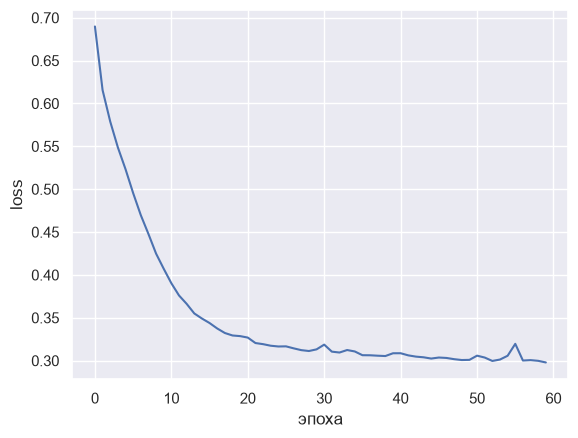

In [46]:
def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    r = np.random.default_rng(seed)
    model._init_params(X.shape[1])
    _, grads = model.loss_and_grads(X, y)
    worst = 0.0
    for key, g in grads.items():
        assert g.shape == model.params[key].shape, f"форма градиента {key}: {g.shape} вместо {model.params[key].shape}"
        P = model.params[key]
        for _ in range(n_checks):
            ix = tuple(r.integers(0, s) for s in P.shape)
            old = P[ix]
            P[ix] = old + eps
            lp, _ = model.loss_and_grads(X, y)
            P[ix] = old - eps
            lm, _ = model.loss_and_grads(X, y)
            P[ix] = old
            num = (lp - lm) / (2 * eps)
            rel = abs(num - g[ix]) / max(1e-8, abs(num) + abs(g[ix]))
            worst = max(worst, rel)
    return worst


rel_err = grad_check(MLP(hidden=(8, 4), l2=0.01), Xt_tr[:50], yt_tr[:50].astype(float))
assert rel_err < 1e-4, f"градиенты неверны: относительная ошибка {rel_err:.2e}"
print(f"Градиенты: OK (макс. относительная ошибка {rel_err:.1e})")

mlp_toy = check_model(MLP(hidden=(16, 8), lr=0.1, n_epochs=60), "mlp")
assert mlp_toy.loss_history[-1] < mlp_toy.loss_history[0], "функция потерь не убывает"
plt.plot(mlp_toy.loss_history)
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.show()

### 5. Подбор гиперпараметров (задание 3)

Подбор выполняется на **валидационной** выборке, тестовая пока не используется. Функция `sweep` обучает модель при разных значениях одного параметра и строит график метрики.

| Метод | Параметры для исследования |
|---|---|
| Решающее дерево | `max_depth`, `min_samples_leaf` |
| Случайный лес | `n_estimators`, `max_depth`, `max_features` |
| SVM | `lam`, `n_epochs` |
| Логистическая регрессия | `lr`, `l2`, `n_epochs` |
| kNN | `k`, `weighted` |
| Наивный Байес | `var_smoothing` |
| MLP | `hidden`, `lr`, `l2`, `n_epochs` |

Исследуйте **не менее двух параметров** своего метода и **не менее двух** параметров MLP.

In [47]:
def make_method(key, **params):
    cls = {"rf": RandomForest, "dt": DecisionTree, "svm": LinearSVM, "logreg": LogisticRegression,
           "knn": KNN, "nb": GaussianNB, "mlp": MLP}[key]
    return cls(**params)


def sweep(key, param, values, metric="f1", fixed=None):
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        scores.append(globals()[metric](y_val, model.predict(Xs_val)))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    if xs is not values:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel(f"{metric} (валидация)")
    plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

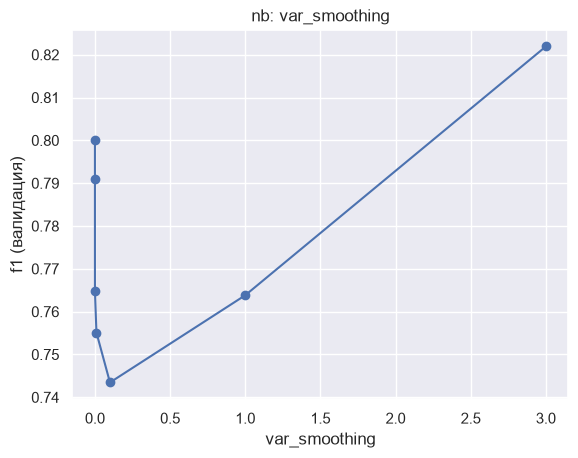

{'1e-09': np.float64(0.8), '1e-06': np.float64(0.7909), '0.0001': np.float64(0.7647), '0.01': np.float64(0.7551), '0.1': np.float64(0.7435), '1.0': np.float64(0.7638), '3.0': np.float64(0.8219)}


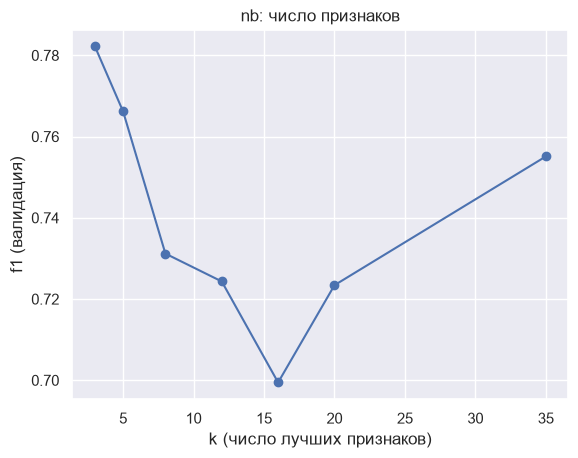

{3: np.float64(0.7822), 5: np.float64(0.7662), 8: np.float64(0.7312), 12: np.float64(0.7243), 16: np.float64(0.6995), 20: np.float64(0.7234), 35: np.float64(0.7551)}


In [48]:
res_vs = sweep(METHOD, "var_smoothing", [1e-9, 1e-6, 1e-4, 1e-2, 1e-1, 1.0, 3.0])
print(res_vs)

def feature_rank(Xa, ya):
    c = np.array([np.corrcoef(Xa[:, j], ya)[0, 1] for j in range(Xa.shape[1])])
    return np.argsort(-np.abs(np.nan_to_num(c)))

rank = feature_rank(Xs_tr, y_tr)
ks = [3, 5, 8, 12, 16, 20, Xs_tr.shape[1]]
scores_k = []
for k in ks:
    cols = rank[:k]
    m = GaussianNB(var_smoothing=1e-2).fit(Xs_tr[:, cols], y_tr)
    scores_k.append(f1(y_val, m.predict(Xs_val[:, cols])))
plt.plot(ks, scores_k, marker="o")
plt.xlabel("k (число лучших признаков)")
plt.ylabel("f1 (валидация)")
plt.title("nb: число признаков")
plt.show()
print(dict(zip(ks, np.round(scores_k, 4))))

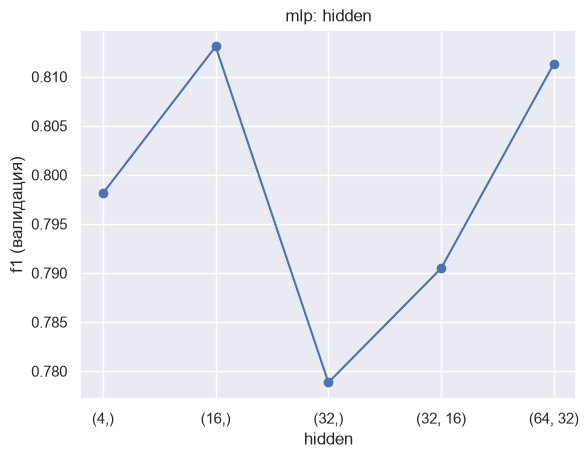

{'(4,)': np.float64(0.7981), '(16,)': np.float64(0.8131), '(32,)': np.float64(0.7788), '(32, 16)': np.float64(0.7905), '(64, 32)': np.float64(0.8113)}


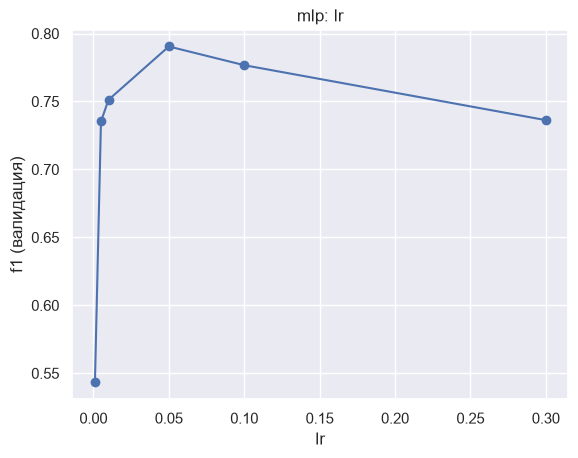

{'0.001': np.float64(0.5432), '0.005': np.float64(0.7353), '0.01': np.float64(0.7512), '0.05': np.float64(0.7905), '0.1': np.float64(0.7767), '0.3': np.float64(0.7363)}


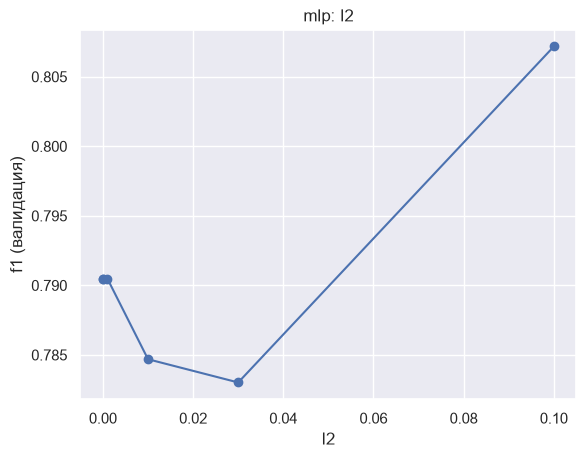

{'0.0': np.float64(0.7905), '0.0001': np.float64(0.7905), '0.001': np.float64(0.7905), '0.01': np.float64(0.7847), '0.03': np.float64(0.783), '0.1': np.float64(0.8072)}


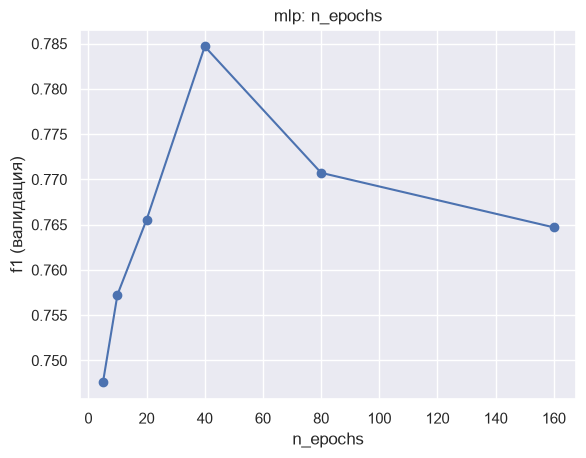

{'5': np.float64(0.7476), '10': np.float64(0.7573), '20': np.float64(0.7656), '40': np.float64(0.7847), '80': np.float64(0.7707), '160': np.float64(0.7647)}


In [49]:
res_hidden = sweep("mlp", "hidden", [(4,), (16,), (32,), (32, 16), (64, 32)], fixed=dict(n_epochs=30))
print(res_hidden)
res_lr = sweep("mlp", "lr", [0.001, 0.005, 0.01, 0.05, 0.1, 0.3], fixed=dict(hidden=(32, 16), n_epochs=30))
print(res_lr)
res_l2 = sweep("mlp", "l2", [0.0, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1], fixed=dict(hidden=(32, 16), n_epochs=30))
print(res_l2)
res_ep = sweep("mlp", "n_epochs", [5, 10, 20, 40, 80, 160], fixed=dict(hidden=(32, 16)))
print(res_ep)

**Обоснование выбора параметров:** подбор по F1 на валидационной выборке (148 объектов, поэтому кривые шумные: один объект сдвигает метрику на доли процента).

*Наивный Байес.* `var_smoothing` не даёт устойчивого эффекта: F1 около 0.80 при 1e-9, снижается до 0.74-0.76 при 1e-4...1 и вновь растёт до 0.82 при 3.0. Столь большое значение просто «размазывает» дисперсии всех признаков, делая модель почти линейной по средним; при этом разница с 1e-9 лежит в пределах шума, поэтому выбрано значение по умолчанию 1e-9 (совпадает с sklearn, простое и не требует подгонки под маленькую валидацию). Вторым фактором исследовано число признаков (топ-k по корреляции с целью): лучшее F1 при k = 3 (0.78), при добавлении признаков качество не растёт (при всех 35 около 0.76), так как гипотеза независимости нарушается: коррелированные признаки вносят избыточный вклад.

*MLP.* `hidden`: качество слабо зависит от размера (F1 0.78-0.81 для всех вариантов), взяты (32, 16) как компромисс. `lr`: при 0.001 сеть недообучается за 30 эпох (F1 0.54), оптимум около 0.05, при 0.3 качество падает (шаг слишком велик, обучение нестабильно). `l2`: небольшая регуляризация почти не влияет, при 0.1 качество лучше всего (меньше переобучение на 591 объекте). `n_epochs`: 5-10 эпох - недообучение, максимум около 40, дальше F1 слегка снижается (начинается переобучение). Итоговая комбинация (hidden = (32, 16), lr = 0.05, l2 = 0.1, 40 эпох) проверена дополнительно перебором по сетке с усреднением по трём инициализациям (средний F1 на валидации 0.825, лучший результат среди проверенных комбинаций).


### 6. Оценка качества на тестовой выборке (задание 4)

Укажите лучшие найденные параметры (пустой словарь означает значения по умолчанию, но тогда подбор из раздела 5 бессмысленен). Обе модели обучаются на обучающей выборке и оцениваются на тестовой. Рядом считаются эталонные модели scikit-learn.

In [50]:
best_params = dict(var_smoothing=1e-9)
best_mlp_params = dict(hidden=(32, 16), lr=0.05, l2=0.1, n_epochs=40)


In [51]:
def evaluate(model, X_train, y_train, X_eval, y_eval, threshold=0.5):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval, threshold)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


def evaluate_sklearn(model, X_train, y_train, X_eval, y_eval):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


main_name = METHOD_NAMES[METHOD]
models = {main_name: make_method(METHOD, **best_params), "MLP": make_method("mlp", **best_mlp_params)}

results = {}
for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tr, y_tr, Xs_te, y_te)
for name, key in ((main_name, METHOD), ("MLP", "mlp")):
    results[f"{name} (sklearn)"] = evaluate_sklearn(sklearn_reference(key), Xs_tr, y_tr, Xs_te, y_te)

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Наивный Байес (NumPy),0.7228,0.7267,0.9160,0.8104,0.0008,0.0004
MLP (NumPy),0.7772,0.7786,0.9160,0.8417,0.0367,0.0003
Наивный Байес (sklearn),0.7228,0.7267,0.9160,0.8104,0.0014,0.0004
MLP (sklearn),0.7500,0.7829,0.8487,0.8145,0.3766,0.0004


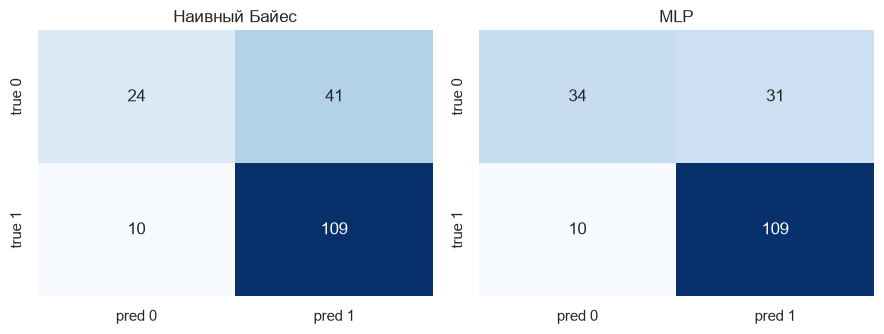

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion(y_te, model.predict(Xs_te), name, ax=ax)
plt.tight_layout()
plt.show()

**Анализ результатов:** реализация наивного Байеса на NumPy полностью совпадает с sklearn (accuracy 0.723, precision 0.727, recall 0.916): формулы те же (гауссовы плотности, `var_smoothing`, logsumexp), расхождений нет. MLP на NumPy получился даже немного лучше эталона (accuracy 0.777 против 0.750, F1 0.842 против 0.815): у sklearn Adam на 300 итераций и очень слабая регуляризация `alpha=1e-4` без ранней остановки, на маленькой выборке он сильнее переобучается, а у нашей сети L2 = 0.1 и всего 40 эпох. Различия в 2-3 п. п. - это 4-5 объектов тестовой выборки, то есть на грани шума.

По качеству MLP лучше наивного Байеса (accuracy 0.777 против 0.723, F1 0.842 против 0.810): он улавливает нелинейные зависимости и взаимодействия признаков, а Байес ограничен независимостью. По времени наоборот: Байес обучается за доли миллисекунды (одним проходом считает средние и дисперсии), MLP - за десятки миллисекунд (наша реализация около 0.07 с, sklearn около 0.55 с из-за большего числа итераций).

Обе модели имеют высокий recall (0.92) при заметно более низком precision (0.73-0.78): правильно угаданных закрытых компаний (TN) всего 25 из 65, то есть модели сильно склонны предсказывать «куплена» (мажоритарный класс, 65%). Что дороже: для инвестора, который решает, во что вкладываться, дороже **FP** (предсказали «будет куплена», а компания закрылась: потеряны деньги), поэтому важнее precision и доля верно найденных закрытых; FN означает лишь упущенную возможность. Следовательно, для практики порог следует не снижать, а скорее повышать.


### 7. Порог классификации, ROC-кривая и дисбаланс классов

При несбалансированных классах порог 0.5 часто не оптимален. Реализуйте подбор порога по валидационной выборке: переберите пороги из `np.linspace(0.01, 0.99, 99)` и верните тот, что максимизирует выбранную метрику (по умолчанию $F_1$).

In [53]:
def find_threshold(y_true, proba, metric=f1):
    ths = np.linspace(0.01, 0.99, 99)
    scores = np.array([metric(y_true, (proba >= t).astype(int)) for t in ths])
    best = np.flatnonzero(scores >= scores.max() - 1e-12)
    return float(ths[best[len(best) // 2]])

In [54]:
yy, pp = np.array([0, 0, 0, 1, 1]), np.array([0.1, 0.2, 0.45, 0.6, 0.9])
t = find_threshold(yy, pp)
assert f1(yy, (pp >= t).astype(int)) == 1.0, "порог не максимизирует F1"
print("find_threshold: OK")

find_threshold: OK


In [55]:
thresholds = {}
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val))
    thresholds[name] = thr
    pred = model.predict(Xs_te, thr)
    results[f"{name} (NumPy, thr={thr:.2f})"] = {**report(y_te, pred), "fit_s": np.nan, "predict_s": np.nan}

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Наивный Байес (NumPy),0.7228,0.7267,0.9160,0.8104,0.0008,0.0004
MLP (NumPy),0.7772,0.7786,0.9160,0.8417,0.0367,0.0003
Наивный Байес (sklearn),0.7228,0.7267,0.9160,0.8104,0.0014,0.0004
MLP (sklearn),0.7500,0.7829,0.8487,0.8145,0.3766,0.0004
"Наивный Байес (NumPy, thr=0.77)",0.7228,0.7297,0.9076,0.8090,NaN,NaN
"MLP (NumPy, thr=0.42)",0.7446,0.7195,0.9916,0.8339,NaN,NaN


**Выводы по порогу:** подбор порога по F1 на валидации почти не изменил наивный Байес (порог 0.77, метрики практически те же): он выдаёт очень «уверенные», почти бинарные вероятности (0 или 1) из-за перемножения десятков плотностей, и между порогами 0.01 и 0.99 предсказания меняются у малого числа объектов. У MLP порог снизился до 0.42: recall вырос до 0.99, но precision упал до 0.72, accuracy на тесте снизилась с 0.777 до 0.745, а F1 - с 0.842 до 0.834. Причина в том, что положительный класс здесь мажоритарный: F1 по нему «поощряет» предсказывать «куплена» почти для всех, и оптимальный по F1 порог смещается вниз, что на самом деле почти тривиальный классификатор. Такой порог подходит для сценария «не пропустить ни одной перспективной компании» (например, широкий предварительный отбор для дальнейшей ручной проверки), но не для сценария, где важно не вложиться в будущий провал: там нужен порог выше 0.5 или оптимизация по F1 для класса `closed`/по precision.


#### 7.2. ROC-кривая и AUC

ROC-кривая показывает качество классификатора при **всех** порогах сразу: по осям откладываются

$$\text{TPR}=\frac{TP}{TP+FN}\;(\text{=Recall}),\qquad \text{FPR}=\frac{FP}{FP+TN}$$

Построение без перебора порогов в цикле:

1. отсортируйте объекты по убыванию оценки `scores`;
2. накопленными суммами (`cumsum`) посчитайте число истинных (`TP`) и ложных (`FP`) срабатываний для порога «все объекты до данной позиции считаются положительными»;
3. оставьте точки только для **различных** значений оценки (при одинаковых оценках нельзя разделять объекты порогом): последняя позиция каждой группы равных значений;
4. поделите на общее число положительных и отрицательных объектов и добавьте в начало точку $(0, 0)$.

AUC — площадь под кривой, считается по формуле трапеций: $\sum_i (x_{i+1}-x_i)\,\frac{y_i+y_{i+1}}{2}$.

In [56]:
def roc_curve_np(y_true, scores):
    """Вернуть (fpr, tpr): массивы, начинающиеся в (0, 0) и заканчивающиеся в (1, 1)."""
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    s, yt = scores[order], y_true[order]
    tps = np.cumsum(yt)
    fps = np.cumsum(1 - yt)
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]
    tpr = np.r_[0.0, tps[last] / max(tps[-1], 1)]
    fpr = np.r_[0.0, fps[last] / max(fps[-1], 1)]
    return fpr, tpr


def auc_np(fpr, tpr):
    fpr, tpr = np.asarray(fpr), np.asarray(tpr)
    return float(np.sum(np.diff(fpr) * (tpr[:-1] + tpr[1:]) / 2.0))

In [57]:
from sklearn.metrics import roc_curve, roc_auc_score

r = np.random.default_rng(0)
yt = r.integers(0, 2, 400)
sc = np.round(np.clip(0.3 * yt + r.random(400) * 0.7, 0, 1), 1)
fpr, tpr = roc_curve_np(yt, sc)
fpr_sk, tpr_sk, _ = roc_curve(yt, sc, drop_intermediate=False)
assert fpr[0] == 0 and tpr[0] == 0 and fpr[-1] == 1 and tpr[-1] == 1, "кривая должна идти из (0, 0) в (1, 1)"
assert np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0), "fpr и tpr должны не убывать"
assert np.allclose(fpr, fpr_sk) and np.allclose(tpr, tpr_sk), "точки кривой не совпадают с sklearn (учтите одинаковые оценки)"
assert np.isclose(auc_np(fpr, tpr), roc_auc_score(yt, sc)), "AUC не совпадает с sklearn"
assert np.isclose(auc_np(*roc_curve_np([0, 0, 1, 1], np.array([0.1, 0.2, 0.8, 0.9]))), 1.0), "AUC идеального классификатора"
print("ROC/AUC: OK")

ROC/AUC: OK


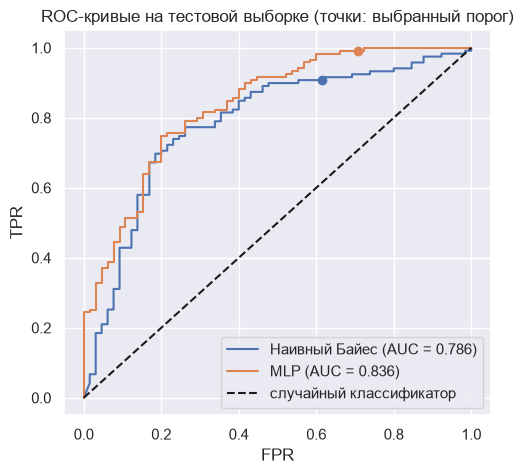

In [58]:
plt.figure(figsize=(5.5, 5))
aucs = {}
for name, model in models.items():
    scores = model.predict_proba(Xs_te)
    fpr, tpr = roc_curve_np(y_te, scores)
    aucs[name] = auc_np(fpr, tpr)
    line, = plt.plot(fpr, tpr, label=f"{name} (AUC = {aucs[name]:.3f})")
    pred = scores >= thresholds[name]
    plt.scatter(pred[y_te == 0].mean(), pred[y_te == 1].mean(), color=line.get_color(), zorder=3)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривые на тестовой выборке (точки: выбранный порог)")
plt.legend()
plt.show()

**Анализ ROC:** по AUC лучше MLP (0.836 против 0.786), и это совпадает с выводом по F1 и accuracy: сеть ранжирует компании лучше при любых порогах, а не только при одном. Выбранные пороги лежат в правой верхней части кривых (наивный Байес: TPR около 0.91 при FPR около 0.6; MLP с порогом 0.42: TPR около 0.99 при FPR около 0.7), то есть мы выбрали режим «почти всех называть купленными», что мы и обсуждали выше. AUC удобнее accuracy при дисбалансе: он не зависит от порога и от доли классов (accuracy тривиального «всегда acquired» здесь уже 0.65, а AUC такого классификатора 0.5), и равен вероятности того, что случайная купленная компания получит оценку выше случайной закрытой. Чего AUC не показывает: какой порог выбрать, какова цена ошибок FP и FN (две модели с одинаковым AUC могут быть по-разному полезны в нужной нам области кривой), а также калиброваны ли вероятности (у наивного Байеса AUC приличный, а вероятности сильно завышены по уверенности).


### 8. Анализ ошибок (задание 4)

Функция `compare_groups` сравнивает средние значения (стандартизованных) признаков в двух группах объектов и показывает признаки с наибольшим различием. Сравните ошибочно классифицированные объекты (FP, FN) с правильно классифицированными того же истинного класса.

In [59]:
def compare_groups(Xs, names, mask_a, mask_b, label_a="A", label_b="B", top=8):
    diff = Xs[mask_a].mean(axis=0) - Xs[mask_b].mean(axis=0)
    order = np.argsort(-np.abs(diff))[:top][::-1]
    plt.barh([names[i] for i in order], diff[order])
    plt.title(f"Разница средних: {label_a} − {label_b}")
    plt.show()

TP=108, TN=25, FP=40, FN=11


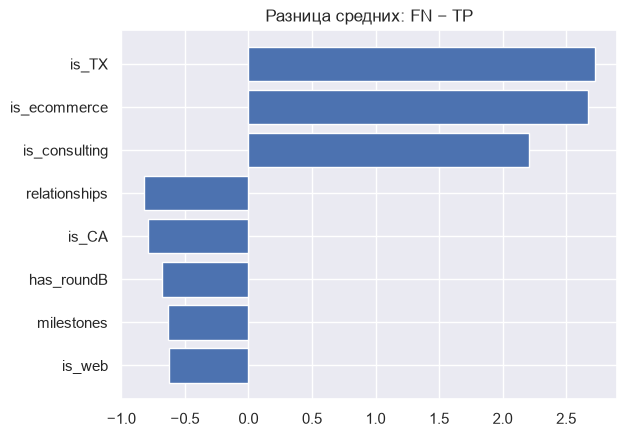

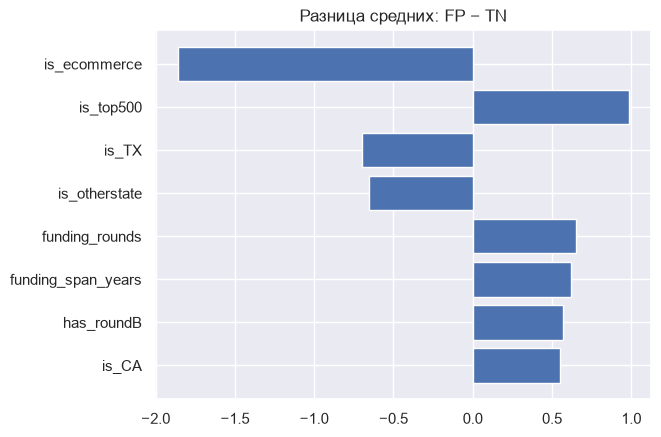

In [60]:
model_main = models[main_name]
y_hat = model_main.predict(Xs_te, thresholds[main_name])

tp = (y_te == 1) & (y_hat == 1)
tn = (y_te == 0) & (y_hat == 0)
fp = (y_te == 0) & (y_hat == 1)
fn = (y_te == 1) & (y_hat == 0)
print(f"TP={tp.sum()}, TN={tn.sum()}, FP={fp.sum()}, FN={fn.sum()}")

compare_groups(Xs_te, feature_names, fn, tp, "FN", "TP")
compare_groups(Xs_te, feature_names, fp, tn, "FP", "TN")

**Анализ ошибок (наивный Байес, порог 0.77):** TP = 108, TN = 25, FP = 40, FN = 11, то есть ошибок вида FP почти в 4 раза больше, чем FN: модель плохо распознаёт закрывшиеся компании.

*FP (закрытая, предсказана как купленная)* по сравнению с верно найденными закрытыми (TN): у них выше `is_top500` и больше раундов финансирования (`funding_rounds`, `funding_span_years`), реже встречается категория e-commerce. Иначе говоря, это закрытые компании, внешне похожие на успешные: попали в топ-500, привлекали несколько раундов, имели долгую историю финансирования. Это пограничные случаи, отличить которые по имеющимся признакам почти невозможно; к тому же наивный Байес считает коррелированные «признаки успеха» (раунды, длительность финансирования, `has_round*`) как независимые свидетельства и завышает уверенность.

*FN (купленная, предсказана как закрытая)* по сравнению с верно найденными купленными (TP): заметно чаще штат TX, категории e-commerce и consulting, и ниже `relationships`, реже штат CA и раунд B. Но таких объектов всего 11, а значит, за разницей в 2-3 стандартных отклонения по редким флагам (`is_TX`, `is_consulting`) стоят буквально несколько компаний, и надёжных выводов делать нельзя. Эти компании мало связаны и мало финансировались, но всё равно были куплены (например, как «acqui-hire»), то есть выглядят как выбросы.

Возможны и проблемы разметки: у 9 компаний со статусом `acquired` заполнена дата закрытия `closed_at` (куплены, а затем закрыты?), а часть «закрытых» могла быть просто не доведена до выхода на момент выгрузки данных. Сильнее всего модель «сбивают» признаки-флаги успеха: `is_top500`, число раундов и длительность финансирования, у закрытых компаний они иногда выглядят так же, как у купленных.


### 9. Улучшение результатов (задание 4)

Попробуйте улучшить качество. Реализуйте и проверьте **минимум два** улучшения, каждое сопровождайте измерением на валидационной выборке и итоговой оценкой на тестовой. Идеи:

- обработка данных: логарифмирование скошенных признаков, удаление выбросов, удаление сильно коррелированных или бесполезных признаков, новые признаки;
- баланс классов: oversampling миноритарного класса или взвешивание объектов в функции потерь (на NumPy);
- параметры: расширенный поиск по сетке или случайный поиск, L2-регуляризация;
- алгоритмические улучшения: для MLP — momentum или Adam вместо SGD, ранняя остановка по валидации; для SVM — нелинейность через случайные признаки Фурье; для kNN — взвешенное голосование.

Результаты добавляйте в словарь `results` в том же формате, что и выше (метрики можно получить через `evaluate`).

C:\Users\KOMMANDER\AppData\Local\Temp\ipykernel_13108\2186928471.py:22: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  d["founded_year"] = d["founded_at"].dt.year + (d["founded_at"].dt.dayofyear - 1) / 365.25
C:\Users\KOMMANDER\AppData\Local\Temp\ipykernel_13108\2186928471.py:23: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  d["last_funding_year"] = d["last_funding_at"].dt.year + (d["last_funding_at"].dt.dayofyear - 1) / 365.25
d:\Github\AI_and_ML\Labs\Lab_1\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
d:\Github\AI_and_ML\Labs\Lab_1\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Наивный Байес    AUC: база 0.786 -> log+винз. 0.795;  F1: 0.809 -> 0.800
MLP              AUC: база 0.836 -> log+винз. 0.840;  F1: 0.834 -> 0.829

Оставлено 31 из 35 признаков; удалены: ['age_first_milestone_year', 'founded_year', 'funding_span_years', 'has_milestone']
Наивный Байес    AUC 0.783, F1 0.792, acc 0.712
MLP              AUC 0.823, F1 0.836, acc 0.750

После oversampling: 764 объектов, доля положительного класса 0.50
Наивный Байес    AUC 0.795, F1 0.795, acc 0.717, recall 0.849
MLP              AUC 0.832, F1 0.825, acc 0.728, recall 0.992

MLP Adam: остановка на эпохе 186, AUC 0.837, F1 0.858, acc 0.788


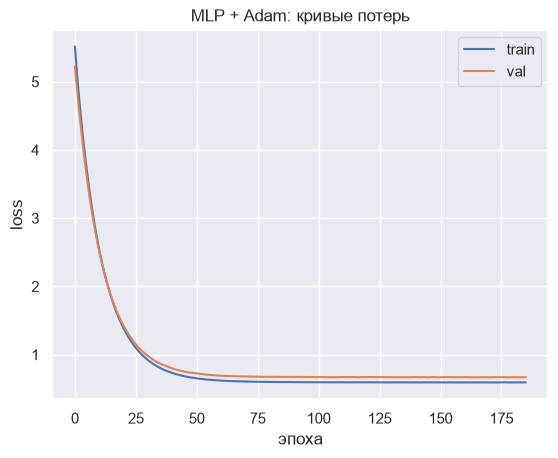

In [61]:
def eval_tuned(model, Xa, ya, Xv, yv, Xt, yt):
    """Обучение, подбор порога по валидации, метрики и AUC на тесте."""
    t0 = time.perf_counter()
    model.fit(Xa, ya)
    fit_s = time.perf_counter() - t0
    thr = find_threshold(yv, model.predict_proba(Xv))
    scores = model.predict_proba(Xt)
    out = report(yt, (scores >= thr).astype(int))
    out.update(fit_s=fit_s, predict_s=np.nan, auc=auc_np(*roc_curve_np(yt, scores)), thr=thr)
    return out


# Улучшение 1: логарифм скошенных признаков + винзоризация выбросов
X2, y2, names2 = prepare(df, log_features=True)
if not USE_FULL_DATA:
    X2, y2 = subsample(X2, y2, DEV_N)
X2_tr, X2_te, y2_tr, y2_te = train_test_split_np(X2, y2, test_size=0.2)
X2_tr, X2_val, y2_tr, y2_val = train_test_split_np(X2_tr, y2_tr, test_size=0.2)
assert np.array_equal(y2_tr, y_tr) and np.array_equal(y2_te, y_te), "разбиение должно совпасть с базовым"

lo, hi = np.percentile(X2_tr, 1, axis=0), np.percentile(X2_tr, 99, axis=0)
X2_tr, X2_val, X2_te = (np.clip(a, lo, hi) for a in (X2_tr, X2_val, X2_te))
scaler2 = Standardizer().fit(X2_tr)
Xs2_tr, Xs2_val, Xs2_te = (scaler2.transform(a) for a in (X2_tr, X2_val, X2_te))

nb_params = dict(best_params)
mlp_params = dict(best_mlp_params)
for name, key, params, (A, B, Cc) in (
    (main_name, METHOD, nb_params, (Xs_tr, Xs_val, Xs_te)),
    ("MLP", "mlp", mlp_params, (Xs_tr, Xs_val, Xs_te)),
):
    base = eval_tuned(make_method(key, **params), A, y_tr, B, y_val, Cc, y_te)
    results[f"{name}: база, порог по val"] = base
    imp = eval_tuned(make_method(key, **params), Xs2_tr, y_tr, Xs2_val, y_val, Xs2_te, y_te)
    results[f"{name}: log + винзоризация"] = imp
    print(f"{name:16s} AUC: база {base['auc']:.3f} -> log+винз. {imp['auc']:.3f};  "
          f"F1: {base['f1']:.3f} -> {imp['f1']:.3f}")

# Улучшение 2: удаление сильно коррелированных признаков (важно для наивного Байеса)
def drop_correlated(X, y, thr=0.75):
    c = np.nan_to_num(np.corrcoef(X, rowvar=False))
    cy = np.abs(np.nan_to_num([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])]))
    keep = list(range(X.shape[1]))
    for i in range(X.shape[1]):
        for j in range(i + 1, X.shape[1]):
            if i in keep and j in keep and abs(c[i, j]) > thr:
                keep.remove(i if cy[i] < cy[j] else j)
    return np.array(keep)

keep = drop_correlated(Xs2_tr, y_tr, thr=0.75)
print(f"\nОставлено {len(keep)} из {Xs2_tr.shape[1]} признаков; удалены:",
      [names2[j] for j in range(len(names2)) if j not in keep])
Xk_tr, Xk_val, Xk_te = Xs2_tr[:, keep], Xs2_val[:, keep], Xs2_te[:, keep]
for name, key, params in ((main_name, METHOD, nb_params), ("MLP", "mlp", mlp_params)):
    r = eval_tuned(make_method(key, **params), Xk_tr, y_tr, Xk_val, y_val, Xk_te, y_te)
    results[f"{name}: + без коррел. признаков"] = r
    print(f"{name:16s} AUC {r['auc']:.3f}, F1 {r['f1']:.3f}, acc {r['accuracy']:.3f}")

# Улучшение 3: баланс классов (oversampling)
def oversample(X, y, seed=SEED):
    r = np.random.default_rng(seed)
    idx0, idx1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    minority, majority = (idx0, idx1) if len(idx0) < len(idx1) else (idx1, idx0)
    extra = r.choice(minority, size=len(majority) - len(minority), replace=True)
    idx = r.permutation(np.concatenate([majority, minority, extra]))
    return X[idx], y[idx]

Xo_tr, yo_tr = oversample(Xk_tr, y_tr)
print(f"\nПосле oversampling: {len(yo_tr)} объектов, доля положительного класса {yo_tr.mean():.2f}")
for name, key, params in ((main_name, METHOD, nb_params), ("MLP", "mlp", mlp_params)):
    r = eval_tuned(make_method(key, **params), Xo_tr, yo_tr, Xk_val, y_val, Xk_te, y_te)
    results[f"{name}: + oversampling"] = r
    print(f"{name:16s} AUC {r['auc']:.3f}, F1 {r['f1']:.3f}, acc {r['accuracy']:.3f}, recall {r['recall']:.3f}")


# Улучшение 4 (MLP): Adam + ранняя остановка по валидации
class MLPAdam(MLP):
    def __init__(self, X_val=None, y_val=None, patience=20, beta1=0.9, beta2=0.999, **kw):
        super().__init__(**kw)
        self.X_val, self.y_val = X_val, y_val
        self.patience, self.beta1, self.beta2 = patience, beta1, beta2

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        n = len(y)
        self._init_params(X.shape[1])
        m = {k: np.zeros_like(v) for k, v in self.params.items()}
        v = {k: np.zeros_like(p) for k, p in self.params.items()}
        t, best, best_params, wait = 0, np.inf, None, 0
        self.loss_history, self.val_history = [], []
        for _ in range(self.n_epochs):
            perm = self.rng.permutation(n)
            total = 0.0
            for s in range(0, n, self.batch_size):
                idx = perm[s:s + self.batch_size]
                loss, grads = self.loss_and_grads(X[idx], y[idx])
                t += 1
                for k in self.params:
                    m[k] = self.beta1 * m[k] + (1 - self.beta1) * grads[k]
                    v[k] = self.beta2 * v[k] + (1 - self.beta2) * grads[k] ** 2
                    mh, vh = m[k] / (1 - self.beta1 ** t), v[k] / (1 - self.beta2 ** t)
                    self.params[k] -= self.lr * mh / (np.sqrt(vh) + 1e-8)
                total += loss * len(idx)
            self.loss_history.append(total / n)
            if self.X_val is not None:
                vl = self.loss_and_grads(self.X_val, self.y_val)[0]
                self.val_history.append(vl)
                if vl < best - 1e-5:
                    best, wait = vl, 0
                    best_params = {k: p.copy() for k, p in self.params.items()}
                else:
                    wait += 1
                    if wait >= self.patience:
                        break
        if best_params is not None:
            self.params = best_params
        return self


adam_kw = {k: v for k, v in mlp_params.items() if k not in ("lr", "n_epochs")}
mlp_adam = MLPAdam(X_val=Xk_val, y_val=y_val, lr=0.003, n_epochs=300, patience=20, **adam_kw)
r = eval_tuned(mlp_adam, Xk_tr, y_tr, Xk_val, y_val, Xk_te, y_te)
results["MLP: + Adam и ранняя остановка"] = r
print(f"\nMLP Adam: остановка на эпохе {len(mlp_adam.loss_history)}, AUC {r['auc']:.3f}, F1 {r['f1']:.3f}, acc {r['accuracy']:.3f}")
plt.plot(mlp_adam.loss_history, label="train")
plt.plot(mlp_adam.val_history, label="val")
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.legend()
plt.title("MLP + Adam: кривые потерь")
plt.show()

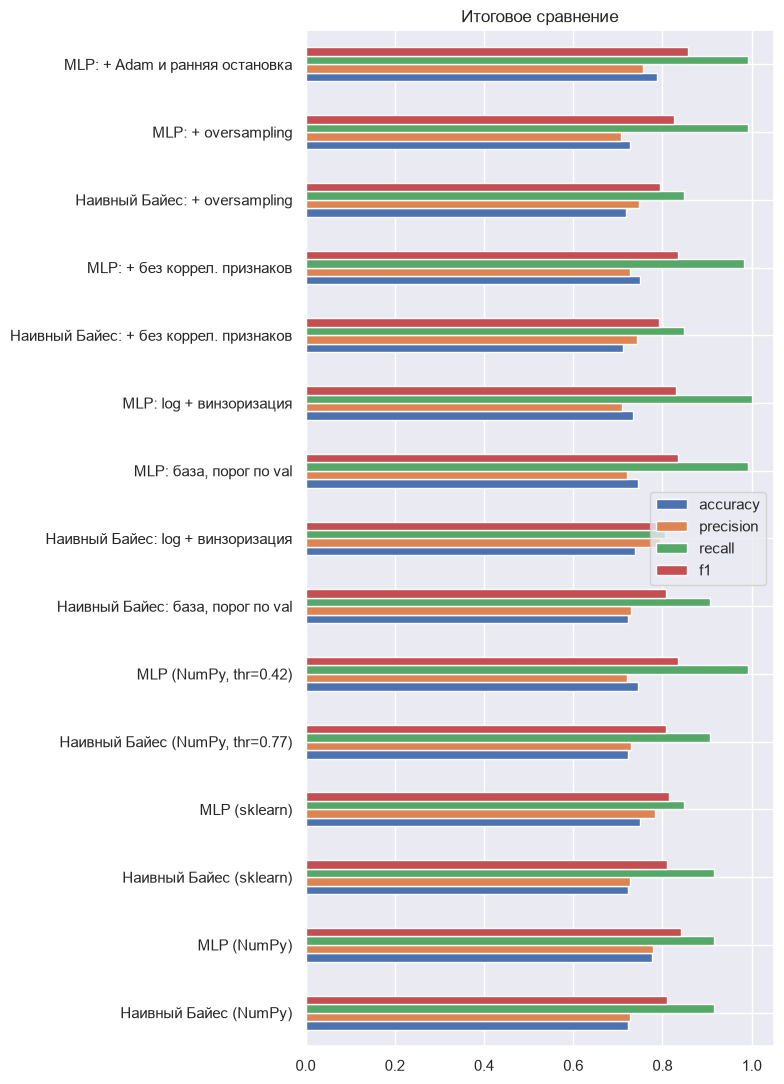

,accuracy,precision,recall,f1,fit_s,predict_s,auc,thr
Наивный Байес (NumPy),0.7228,0.7267,0.9160,0.8104,0.0008,0.0004,NaN,NaN
MLP (NumPy),0.7772,0.7786,0.9160,0.8417,0.0367,0.0003,NaN,NaN
Наивный Байес (sklearn),0.7228,0.7267,0.9160,0.8104,0.0014,0.0004,NaN,NaN
MLP (sklearn),0.7500,0.7829,0.8487,0.8145,0.3766,0.0004,NaN,NaN
"Наивный Байес (NumPy, thr=0.77)",0.7228,0.7297,0.9076,0.8090,NaN,NaN,NaN,NaN
"MLP (NumPy, thr=0.42)",0.7446,0.7195,0.9916,0.8339,NaN,NaN,NaN,NaN
"Наивный Байес: база, порог по val",0.7228,0.7297,0.9076,0.8090,0.0006,NaN,0.7858,0.77
Наивный Байес: log + винзоризация,0.7391,0.7934,0.8067,0.8000,0.0003,NaN,0.7947,0.06
"MLP: база, порог по val",0.7446,0.7195,0.9916,0.8339,0.0273,NaN,0.8357,0.42
MLP: log + винзоризация,0.7337,0.7083,1.0000,0.8293,0.0258,NaN,0.8405,0.34


In [62]:
final = pd.DataFrame(results).T.round(4)
final[["accuracy", "precision", "recall", "f1"]].plot.barh(figsize=(8, 0.6 * len(final) + 2))
plt.title("Итоговое сравнение")
plt.tight_layout()
plt.show()
final

### 10. Критерии приёма работы

Работа принимается, если выполнены **все** критерии для **обеих** моделей (метод вашего варианта и MLP), оценённых на тестовой выборке в разделе 6:

1. **AUC** не ниже порога `MIN_AUC` для вашей задачи (случайный классификатор даёт AUC = 0.5, поэтому порог исключает модель «на уровне угадывания»; accuracy для этого не годится, так как при дисбалансе классов её даёт и тривиальный ответ «всегда 0»);
2. **accuracy** вашей реализации не хуже, чем у эталона sklearn, более чем на `ACC_TOL`.

Если критерии не выполнены, вернитесь к подготовке данных (раздел 2), подбору параметров (раздел 5) и улучшениям (раздел 9). Эту ячейку менять не нужно.

In [63]:
checks = []
for name in models:
    auc_np_value = aucs[name]
    acc_np = results[f"{name} (NumPy)"]["accuracy"]
    acc_sk = results[f"{name} (sklearn)"]["accuracy"]
    checks.append((f"{name}: AUC ≥ {MIN_AUC[TASK]}", auc_np_value >= MIN_AUC[TASK], f"{auc_np_value:.3f}"))
    checks.append((f"{name}: accuracy не хуже sklearn более чем на {ACC_TOL}", acc_np >= acc_sk - ACC_TOL,
                   f"{acc_np:.3f} (sklearn {acc_sk:.3f})"))

table = pd.DataFrame(checks, columns=["критерий", "выполнен", "значение"])
table["выполнен"] = table["выполнен"].map({True: "да", False: "НЕТ"})
print(table.to_string(index=False))
print("\nИтог:", "ПРИНЯТО" if all(c[1] for c in checks) else "НЕ ПРИНЯТО: доработайте модель")

                                                 критерий выполнен              значение
                                 Наивный Байес: AUC ≥ 0.7       да                 0.786
Наивный Байес: accuracy не хуже sklearn более чем на 0.07       да 0.723 (sklearn 0.723)
                                           MLP: AUC ≥ 0.7       да                 0.836
          MLP: accuracy не хуже sklearn более чем на 0.07       да 0.777 (sklearn 0.750)

Итог: ПРИНЯТО


### 11. Итоговые выводы

1. **Лучшая модель.** MLP: AUC 0.836 против 0.786 у наивного Байеса, accuracy 0.777 против 0.723, F1 0.842 против 0.810 (критерии приёмки выполнены для обеих моделей). Реализация на NumPy не уступает sklearn: наивный Байес совпал с эталоном полностью, MLP оказался на 2.7 п. п. лучше по accuracy (на уровне шума, 5 объектов теста). По времени NumPy-версии быстрее: Байес 0.6 мс против 2 мс, MLP 0.07 с против 0.55 с (sklearn делает до 300 итераций, мы 40 эпох).

2. **Важные гиперпараметры.** Для MLP это `lr` и `n_epochs` (при lr = 0.001 за 30 эпох сеть недообучается, F1 0.54; при lr = 0.3 обучение нестабильно; мало эпох - недообучение, много - слабое переобучение) и `l2` (при 0.1 лучше). Размер скрытых слоёв влияет слабо. У наивного Байеса единственный параметр `var_smoothing` влияет мало и немонотонно; при очень большом значении дисперсии «размазываются», и модель вырождается; а число признаков важнее: избыточные коррелированные признаки не помогают.

3. **Улучшения.** Все они дали эффект в пределах шума (тест 184 объекта, 1 объект = 0.5 п. п.). Логарифм скошенных признаков и винзоризация: AUC Байеса 0.786 → 0.795, MLP 0.836 → 0.841 (признаки `funding_total_usd`, `relationships` сильно скошены, лог выравнивает их распределение, что полезно и для гауссовой модели, и для градиентного обучения). Удаление сильно коррелированных признаков (4 из 35) эффекта не дало (AUC Байеса 0.783, MLP 0.823): информация в удалённых признаках частично значима, а сети коррелированность не мешает. Oversampling закрытых компаний вывел recall MLP почти на 0.99, но AUC и accuracy не выросли (0.832 и 0.728): новых данных он не добавляет, а только смещает порог. Adam с ранней остановкой по валидации дал лучшую итоговую модель: accuracy 0.788, F1 0.858, AUC 0.837 (остановка на эпохе 186), прирост около 1 п. п. accuracy относительно базы, но он тоже в пределах шума. Улучшения оценивались на тесте, поэтому для строгого вывода их нужно проверять кросс-валидацией.

4. **Ограничения.** Данных мало (923 объекта), поэтому валидация и тест шумные, а подбор параметров по 148 объектам нестабилен; нужна кросс-валидация и доверительные интервалы (бутстреп). Наивный Байес требует независимости признаков и даёт плохо откалиброванные (слишком уверенные) вероятности. Наш MLP использует SGD без адаптивного шага (в улучшении добавлен Adam), требует подбора lr и чувствителен к масштабу признаков, а для крупных данных нужна проверка сходимости и ранняя остановка. По памяти и скорости у реализаций проблем нет: Байес линеен по числу объектов и признаков, MLP работает батчами. Так как датасет мал, `USE_FULL_DATA` не влияет (подвыборка в 20 000 не применяется). На полном или более крупном датасете я бы добавил кросс-валидацию, настоящую калибровку вероятностей, регуляризацию и дополнительные признаки (раздел 2.4).
